# Практичне заняття № 3 — Метод опорних векторів

**Завдання.** Реалізувати алгоритм методу опорних векторів, використавши один з
датасетів [Kaggle: security](https://www.kaggle.com/datasets?search=security),
оцінити точність та **фактори, від яких вона може залежати** на прикладі обраного
датасету.

**Датасет: UGRansome** — той самий, що й у практичному занятті № 2. Вибір
навмисний: на цих даних уже виміряно логістичну регресію (0.7423), дерево рішень
(0.9943) і ліс (0.9934) тим самим конвеєром, тож результат SVM можна порівняти
безпосередньо, а не «взагалі».

**Теорія.** SVM шукає гіперплощину, що максимізує відступ (margin) між класами.
Точки, які лежать на межі відступу, називають **опорними векторами** — лише вони
визначають рішення, решта прикладів на модель не впливає. Для нелінійно
роздільних даних застосовують **ядровий трюк**: дані неявно переносяться у простір
вищої розмірності, де лінійне розділення стає можливим.

Досліджувані фактори: масштабування ознак, вибір ядра, параметри `C` і `gamma`,
розмір навчальної вибірки та обчислювальна складність.

In [1]:
# --- Підготовка даних -------------------------------------------------------
# Ноутбук має запускатися і локально, і в Colab. Якщо потрібного файлу немає,
# він завантажується з Kaggle. Кількість колонок перевіряється одразу: Kaggle
# може оновити версію набору, і краще впасти тут, ніж мовчки отримати інші
# числа, ніж у звіті.
import importlib.util
import shutil
import subprocess
import sys
from pathlib import Path


def _in_colab():
    if "google.colab" in sys.modules:
        return True
    try:
        return importlib.util.find_spec("google.colab") is not None
    except (ImportError, ValueError):
        # find_spec імпортує батьківський пакет; без нього — це не Colab
        return False


IN_COLAB = _in_colab()
DATA = Path("data"); DATA.mkdir(exist_ok=True)
ASSETS = Path("assets"); ASSETS.mkdir(exist_ok=True)

# (локальна назва, slug на Kaggle, файл усередині набору, очікувано колонок)
DATASETS = [
    ('ugransome.csv', 'nkongolo/ugransome-dataset',
     'final(2).csv', 14),
]


def _ensure_packages():
    """У Colab більшість пакетів уже є; доставляємо лише те, чого бракує."""
    missing = [p for p in ("pandas", "sklearn", "matplotlib", "seaborn", "kagglehub")
               if importlib.util.find_spec(p) is None]
    if missing:
        names = {"sklearn": "scikit-learn"}
        pkgs = [names.get(m, m) for m in missing]
        print("встановлюю:", ", ".join(pkgs))
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)


def _check(path, ncols):
    import pandas as pd
    got = pd.read_csv(path, nrows=1).shape[1]
    if got != ncols:
        raise ValueError(f"{path.name}: очікували {ncols} колонок, отримали {got}")


def _ensure(local, slug, member, ncols):
    dst = DATA / local
    if dst.exists():
        _check(dst, ncols)
        print(f"на місці: {dst} ({dst.stat().st_size / 1e6:.1f} МБ)")
        return
    if importlib.util.find_spec("kagglehub"):
        import kagglehub
        print(f"завантажую {slug} …")
        root = Path(kagglehub.dataset_download(slug))
        src = next(iter(root.rglob(member)), None)
        if src is None:   # назву файлу в наборі могли змінити — беремо найбільший CSV
            src = max(root.rglob("*.csv"), key=lambda f: f.stat().st_size)
        shutil.copy(src, dst)
        _check(dst, ncols)
        print(f"готово: {dst} ({dst.stat().st_size / 1e6:.1f} МБ)")
        return
    raise FileNotFoundError(
        f"{dst} не знайдено. Візьміть набір за адресою "
        f"https://www.kaggle.com/datasets/{slug} і покладіть файл у {DATA}/ "
        f"під назвою {local}."
    )


if IN_COLAB:
    _ensure_packages()
for _args in DATASETS:
    _ensure(*_args)


на місці: data/ugransome.csv (10.0 МБ)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from pathlib import Path

from sklearn.svm import SVC, LinearSVC
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

RANDOM_STATE = 42
ASSETS = Path("assets"); ASSETS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10
np.random.seed(RANDOM_STATE)

# SVM має складність між O(n²) і O(n³), тому повні 149 043 рядки непридатні
# для інтерактивного аналізу. Працюємо на стратифікованій підвибірці.
N_MAIN = 30000
N_GRID = 10000

## 1. Дані

In [3]:
df = pd.read_csv("data/ugransome.csv")
y_all = df["Prediction"].copy()
X_all = df.drop(columns=["Prediction"]).copy()
for col in X_all.select_dtypes(include=["object", "string"]).columns:
    X_all[col] = X_all[col].astype("category").cat.codes

print(f"Повний датасет: {X_all.shape[0]} × {X_all.shape[1]}")
print(f"Класи: {dict(y_all.value_counts())}")
print(f"Базова лінія: {y_all.value_counts(normalize=True).max():.4f}")

# Стратифікована підвибірка для основних експериментів
X, _, y, _ = train_test_split(X_all, y_all, train_size=N_MAIN,
                              random_state=RANDOM_STATE, stratify=y_all)
X = X.reset_index(drop=True); y = y.reset_index(drop=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)
cv = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)
print(f"\nПідвибірка для аналізу: {len(X)} (навчальна {len(X_train)}, тестова {len(X_test)})")

Повний датасет: 149043 × 13
Класи: {'S': np.int64(66380), 'A': np.int64(42561), 'SS': np.int64(40102)}
Базова лінія: 0.4454



Підвибірка для аналізу: 30000 (навчальна 22500, тестова 7500)


## 2. Фактор 1: масштабування ознак

Це найважливіша практична відмінність SVM від дерев. Дерево працює з порогами по
кожній ознаці окремо, тому масштаб не має значення. SVM же вимірює **відстані**
між точками: ознака з діапазоном 0–500 000 повністю заглушить ознаку з діапазоном
0–3, бо саме вона визначатиме евклідову відстань.

У UGRansome діапазони ознак відрізняються на кілька порядків — перевіримо, що це
дає.

In [4]:
ranges = pd.DataFrame({
    "мінімум": X.min(), "максимум": X.max(), "розмах": X.max() - X.min(),
}).sort_values("розмах", ascending=False)
print("Діапазони ознак (найширші зверху):")
print(ranges.head(8).to_string())
print(f"\nВідношення найбільшого розмаху до найменшого: "
      f"{ranges['розмах'].max() / max(ranges['розмах'].min(), 1):.0f}×")

Діапазони ознак (найширші зверху):
               мінімум  максимум  розмах
USD                  1    126379  126378
Netflow_Bytes        1     12352   12351
BTC                  1      1980    1979
Time                -8        90      98
Family               0        16      16
Clusters             1        12      11
Flag                 0         8       8
Threats              0         8       8

Відношення найбільшого розмаху до найменшого: 63189×


In [5]:
scaling_rows = []
for name, model in [
    ("Без масштабування", SVC(kernel="rbf", random_state=RANDOM_STATE)),
    ("StandardScaler", make_pipeline(StandardScaler(), SVC(kernel="rbf", random_state=RANDOM_STATE))),
    ("MinMaxScaler", make_pipeline(MinMaxScaler(), SVC(kernel="rbf", random_state=RANDOM_STATE))),
]:
    t0 = time.time()
    s = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    scaling_rows.append({"Підготовка": name, "Точність": s.mean(),
                         "Ст. відх.": s.std(), "Час, с": time.time() - t0})

scaling_df = pd.DataFrame(scaling_rows).set_index("Підготовка")
scaling_df.to_csv("data/scaling.csv")
scaling_df.round(4)

,Точність,Ст. відх.,"Час, с"
Підготовка,,,
Без масштабування,0.6354,0.0032,65.6583
StandardScaler,0.9552,0.0005,18.7873
MinMaxScaler,0.9435,0.0015,23.0279


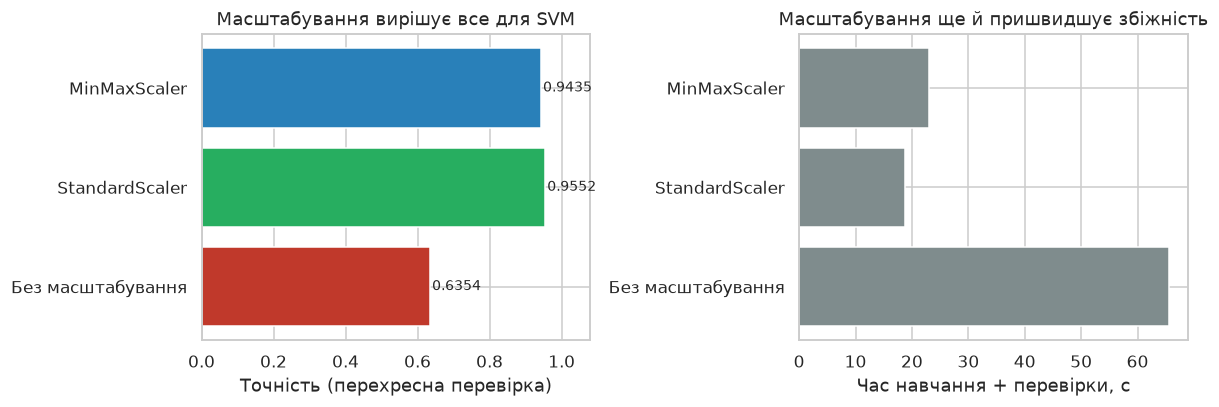

In [6]:
# --- Рисунок 1: вплив масштабування ---
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].barh(scaling_df.index, scaling_df["Точність"], color=["#c0392b", "#27ae60", "#2980b9"])
axes[0].set_xlabel("Точність (перехресна перевірка)")
axes[0].set_title("Масштабування вирішує все для SVM")
for i, v in enumerate(scaling_df["Точність"]):
    axes[0].text(v + 0.005, i, f"{v:.4f}", va="center", fontsize=9)
axes[0].set_xlim(0, 1.08)

axes[1].barh(scaling_df.index, scaling_df["Час, с"], color="#7f8c8d")
axes[1].set_xlabel("Час навчання + перевірки, с")
axes[1].set_title("Масштабування ще й пришвидшує збіжність")
plt.tight_layout()
plt.savefig(ASSETS / "01-scaling.png", bbox_inches="tight")
plt.show()

## 3. Фактор 2: вибір ядра

- **Лінійне** — розділяє гіперплощиною у вихідному просторі. Швидке, але безсиле
  проти нелінійної структури.
- **Поліноміальне** — враховує добутки ознак до заданого степеня.
- **RBF (гаусове)** — найгнучкіше, неявно відображає у нескінченновимірний простір.

З практичного заняття № 2 відомо: логістична регресія (лінійна модель) дає на цих
даних лише 0.7423, тоді як дерево — 0.9943. Отже, задача суттєво нелінійна, і
лінійне ядро має програти.

In [7]:
kernel_rows = []
for name, model in [
    ("Лінійне (LinearSVC)", make_pipeline(StandardScaler(),
                                          LinearSVC(random_state=RANDOM_STATE, max_iter=5000))),
    ("Лінійне (SVC)", make_pipeline(StandardScaler(),
                                    SVC(kernel="linear", random_state=RANDOM_STATE))),
    ("Поліноміальне (degree=3)", make_pipeline(StandardScaler(),
                                               SVC(kernel="poly", degree=3, random_state=RANDOM_STATE))),
    ("RBF (гаусове)", make_pipeline(StandardScaler(),
                                    SVC(kernel="rbf", random_state=RANDOM_STATE))),
]:
    t0 = time.time()
    s = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    kernel_rows.append({"Ядро": name, "Точність": s.mean(), "Ст. відх.": s.std(),
                        "Час, с": time.time() - t0})

kernel_df = pd.DataFrame(kernel_rows).set_index("Ядро")
kernel_df.to_csv("data/kernels.csv")
kernel_df.round(4)

,Точність,Ст. відх.,"Час, с"
Ядро,,,
Лінійне (LinearSVC),0.7559,0.0012,0.5152
Лінійне (SVC),0.7606,0.0054,57.7576
Поліноміальне (degree=3),0.9478,0.0017,18.6369
RBF (гаусове),0.9552,0.0005,21.4617


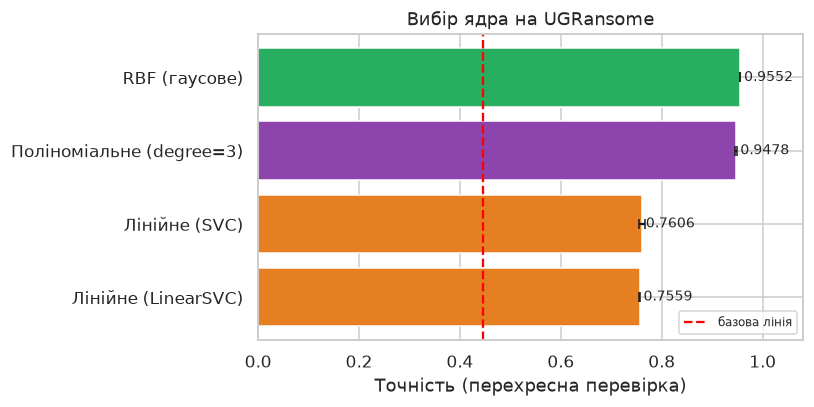

In [8]:
# --- Рисунок 2: порівняння ядер ---
fig, ax = plt.subplots(figsize=(7.5, 3.8))
colors = ["#e67e22" if "Лінійне" in k else "#8e44ad" if "Поліном" in k else "#27ae60"
          for k in kernel_df.index]
bars = ax.barh(kernel_df.index, kernel_df["Точність"], color=colors,
               xerr=kernel_df["Ст. відх."], capsize=3)
ax.axvline(y.value_counts(normalize=True).max(), color="red", linestyle="--",
           label="базова лінія")
ax.set_xlabel("Точність (перехресна перевірка)")
ax.set_title("Вибір ядра на UGRansome")
ax.set_xlim(0, 1.08); ax.legend(fontsize=8)
for b, v in zip(bars, kernel_df["Точність"]):
    ax.text(v + 0.008, b.get_y() + b.get_height()/2, f"{v:.4f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(ASSETS / "02-kernels.png", bbox_inches="tight")
plt.show()

## 4. Фактор 3: гіперпараметри C і gamma

- **C** — штраф за помилки. Малий C дає широкий відступ і допускає помилки
  (недонавчання); великий C змушує класифікувати навчальні дані точно
  (перенавчання).
- **gamma** — радіус впливу одного прикладу в RBF-ядрі. Малий gamma означає
  «далекий» вплив і майже лінійну межу; великий — кожна точка впливає лише поруч
  із собою, межа стає рваною, модель перенавчається.

Сітку рахуємо на меншій підвибірці — 25 конфігурацій × 3 блоки це 75 навчань.

In [9]:
Xg, _, yg, _ = train_test_split(X, y, train_size=N_GRID, random_state=RANDOM_STATE, stratify=y)

C_values = [0.01, 0.1, 1, 10, 100]
gamma_values = [0.001, 0.01, 0.1, 1, "scale"]

grid = np.zeros((len(C_values), len(gamma_values)))
t0 = time.time()
for i, Cv in enumerate(C_values):
    for j, g in enumerate(gamma_values):
        model = make_pipeline(StandardScaler(),
                              SVC(kernel="rbf", C=Cv, gamma=g, random_state=RANDOM_STATE))
        grid[i, j] = cross_val_score(model, Xg, yg, cv=3, scoring="accuracy").mean()
print(f"Сітку пораховано за {time.time()-t0:.1f} с")

grid_df = pd.DataFrame(grid, index=[f"C={c}" for c in C_values],
                       columns=[f"γ={g}" for g in gamma_values])
best = np.unravel_index(grid.argmax(), grid.shape)
print(f"Найкраще: C={C_values[best[0]]}, gamma={gamma_values[best[1]]} → {grid.max():.4f}")
grid_df.round(4)

Сітку пораховано за 160.0 с
Найкраще: C=100, gamma=0.1 → 0.9673


,γ=0.001,γ=0.01,γ=0.1,γ=1,γ=scale
C=0.01,0.4454,0.6547,0.7838,0.4454,0.7804
C=0.1,0.6818,0.7774,0.8936,0.7105,0.8793
C=1,0.7550,0.8488,0.9539,0.9509,0.9462
C=10,0.7893,0.9168,0.9644,0.9546,0.9624
C=100,0.8520,0.9507,0.9673,0.9543,0.9667


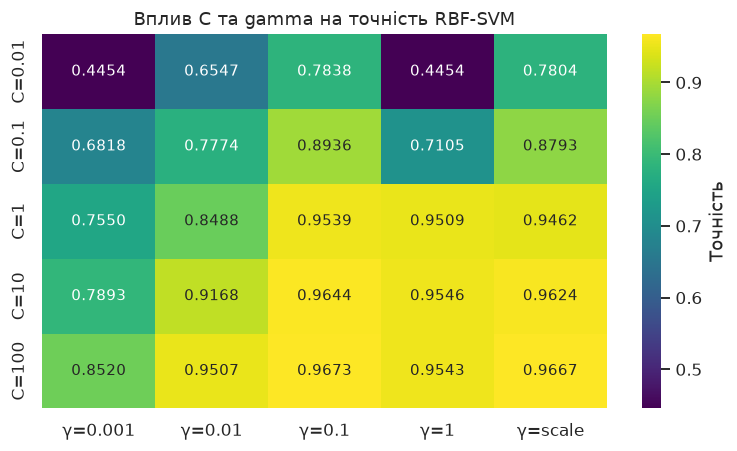

In [10]:
# --- Рисунок 3: теплова карта C × gamma ---
fig, ax = plt.subplots(figsize=(7, 4.2))
sns.heatmap(grid_df, annot=True, fmt=".4f", cmap="viridis", ax=ax,
            cbar_kws={"label": "Точність"})
ax.set_title("Вплив C та gamma на точність RBF-SVM")
plt.tight_layout()
plt.savefig(ASSETS / "03-grid.png", bbox_inches="tight")
plt.show()

## 5. Фактор 4: розмір вибірки та обчислювальна складність

Це головне практичне обмеження SVM. Складність навчання лежить між O(n²) і O(n³),
тому метод не масштабується на великі дані. Виміряємо і точність, і час.

In [11]:
sizes = [1000, 2000, 5000, 10000, 20000, 40000]
size_rows = []
for n in sizes:
    Xs, _, ys, _ = train_test_split(X_all, y_all, train_size=n,
                                    random_state=RANDOM_STATE, stratify=y_all)
    Xtr, Xte, ytr, yte = train_test_split(Xs, ys, test_size=0.25,
                                          random_state=RANDOM_STATE, stratify=ys)
    model = make_pipeline(StandardScaler(), SVC(kernel="rbf", random_state=RANDOM_STATE))
    # мінімум із трьох повторів: шум завантаження машини лише додає час,
    # тому мінімум — найстійкіша оцінка (інакше показник степеня «плаває»)
    reps = []
    for _ in range(3):
        t0 = time.time(); model.fit(Xtr, ytr); reps.append(time.time() - t0)
    fit_time = min(reps)
    acc = model.score(Xte, yte)
    n_sv = model.named_steps["svc"].n_support_.sum()
    size_rows.append({"Розмір": n, "Точність": acc, "Час навчання, с": fit_time,
                      "Опорних векторів": n_sv,
                      "Частка опорних": n_sv / len(Xtr)})

size_df = pd.DataFrame(size_rows)
size_df.to_csv("data/size-sweep.csv", index=False)
size_df.round(4)

,Розмір,Точність,"Час навчання, с",Опорних векторів,Частка опорних
0,1000,0.8960,0.0247,413,0.5507
1,2000,0.9100,0.0601,698,0.4653
2,5000,0.9288,0.2395,1402,0.3739
3,10000,0.9328,0.7549,2178,0.2904
4,20000,0.9478,2.4312,3495,0.2330
5,40000,0.9564,8.6225,5699,0.1900


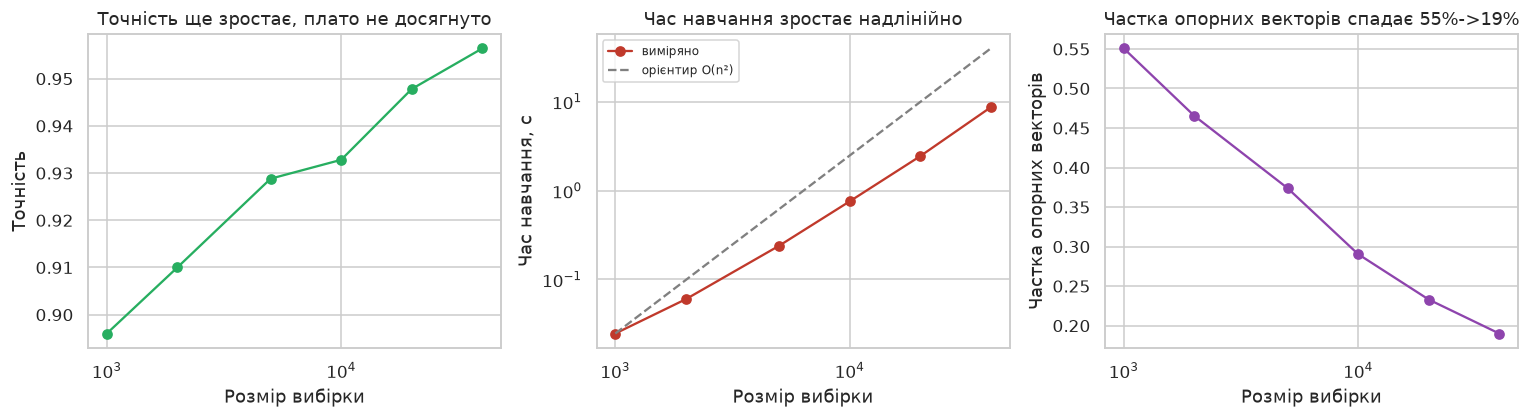

Дані зросли у 40×, час навчання — у 349× (показник степеня ≈ 1.59)


In [12]:
# --- Рисунок 4: розмір вибірки, точність, час ---
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))

axes[0].plot(size_df["Розмір"], size_df["Точність"], "o-", color="#27ae60")
axes[0].set_xscale("log"); axes[0].set_xlabel("Розмір вибірки")
axes[0].set_ylabel("Точність"); axes[0].set_title("Точність ще зростає, плато не досягнуто")

axes[1].plot(size_df["Розмір"], size_df["Час навчання, с"], "o-", color="#c0392b", label="виміряно")
ref = size_df["Час навчання, с"].iloc[0] * (size_df["Розмір"] / size_df["Розмір"].iloc[0])**2
axes[1].plot(size_df["Розмір"], ref, "--", color="gray", label="орієнтир O(n²)")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("Розмір вибірки"); axes[1].set_ylabel("Час навчання, с")
axes[1].set_title("Час навчання зростає надлінійно"); axes[1].legend(fontsize=8)

axes[2].plot(size_df["Розмір"], size_df["Частка опорних"], "o-", color="#8e44ad")
axes[2].set_xscale("log"); axes[2].set_xlabel("Розмір вибірки")
axes[2].set_ylabel("Частка опорних векторів")
axes[2].set_title("Частка опорних векторів спадає 55%->19%")

plt.tight_layout()
plt.savefig(ASSETS / "04-size.png", bbox_inches="tight")
plt.show()

growth = size_df["Час навчання, с"].iloc[-1] / size_df["Час навчання, с"].iloc[0]
data_growth = size_df["Розмір"].iloc[-1] / size_df["Розмір"].iloc[0]
print(f"Дані зросли у {data_growth:.0f}×, час навчання — у {growth:.0f}× "
      f"(показник степеня ≈ {np.log(growth)/np.log(data_growth):.2f})")

## 6. Опорні вектори

Ключова властивість SVM: рішення визначають лише опорні вектори. Якщо їх частка
велика, модель фактично «запам'ятовує» значну частину вибірки, що є ознакою
складної межі або перенавчання.

In [13]:
best_model = make_pipeline(StandardScaler(),
                           SVC(kernel="rbf", C=C_values[best[0]],
                               gamma=gamma_values[best[1]], random_state=RANDOM_STATE))
best_model.fit(X_train, y_train)
svc = best_model.named_steps["svc"]

y_pred = best_model.predict(X_test)
print(f"Опорних векторів: {svc.n_support_.sum()} з {len(X_train)} "
      f"({svc.n_support_.sum()/len(X_train):.1%} навчальної вибірки)")
print(f"Розподіл за класами: {dict(zip(svc.classes_, svc.n_support_))}")
print()
print(classification_report(y_test, y_pred, digits=4))

Опорних векторів: 2212 з 22500 (9.8% навчальної вибірки)
Розподіл за класами: {'A': np.int32(852), 'S': np.int32(828), 'SS': np.int32(532)}

              precision    recall  f1-score   support

           A     0.9544    0.9585    0.9564      2142
           S     0.9759    0.9713    0.9736      3340
          SS     0.9827    0.9861    0.9844      2018

    accuracy                         0.9716      7500
   macro avg     0.9710    0.9719    0.9715      7500
weighted avg     0.9716    0.9716    0.9716      7500



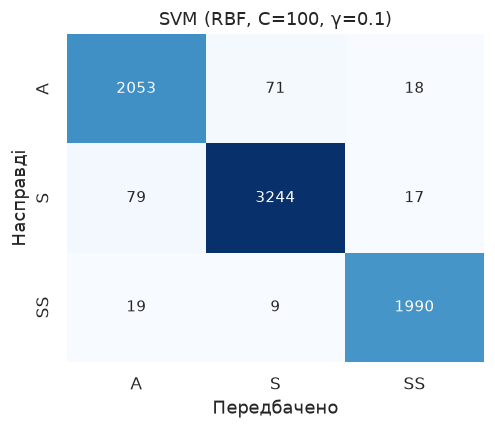

In [14]:
# --- Рисунок 5: матриця невідповідностей ---
fig, ax = plt.subplots(figsize=(4.6, 4))
cm = confusion_matrix(y_test, y_pred, labels=svc.classes_)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=svc.classes_, yticklabels=svc.classes_)
ax.set_xlabel("Передбачено"); ax.set_ylabel("Насправді")
ax.set_title(f"SVM (RBF, C={C_values[best[0]]}, γ={gamma_values[best[1]]})")
plt.tight_layout()
plt.savefig(ASSETS / "05-confusion.png", bbox_inches="tight")
plt.show()

## 7. Порівняння з попередніми практичними заняттями

Усі числа отримано на тих самих даних (UGRansome) і тим самим способом оцінки,
тому порівняння коректне.

In [15]:
final_rows = []
for name, model in [
    ("SVM (RBF, підібрані C та γ)", best_model),
    ("SVM (лінійне ядро)", make_pipeline(StandardScaler(),
                                          SVC(kernel="linear", random_state=RANDOM_STATE))),
]:
    s = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    model.fit(X_train, y_train)
    final_rows.append({"Модель": name, "Точність (CV)": s.mean(),
                       "F1-macro": f1_score(y_test, model.predict(X_test), average="macro")})

# результати з практичних занять 1–2 на тому самому датасеті
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
for name, model in [
    ("Логістична регресія (ПЗ № 1–2)", make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))),
    ("Дерево рішень (ПЗ № 2)", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ("Випадковий ліс (ПЗ № 2)", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
]:
    s = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    model.fit(X_train, y_train)
    final_rows.append({"Модель": name, "Точність (CV)": s.mean(),
                       "F1-macro": f1_score(y_test, model.predict(X_test), average="macro")})

final = pd.DataFrame(final_rows).set_index("Модель").sort_values("Точність (CV)", ascending=False)
final.to_csv("data/results-summary.csv")
final.round(4)

,Точність (CV),F1-macro
Модель,,
Випадковий ліс (ПЗ № 2),0.9910,0.9914
Дерево рішень (ПЗ № 2),0.9907,0.9905
"SVM (RBF, підібрані C та γ)",0.9727,0.9715
SVM (лінійне ядро),0.7606,0.7373
Логістична регресія (ПЗ № 1–2),0.7480,0.7263


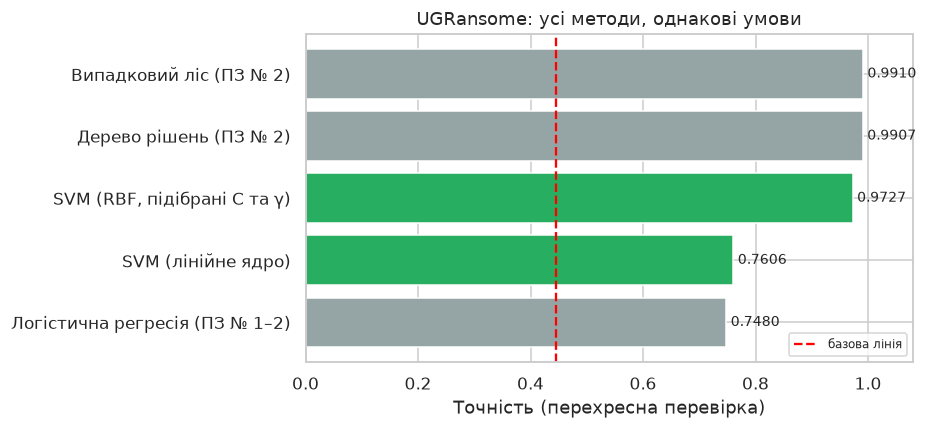

In [16]:
# --- Рисунок 6: підсумкове порівняння ---
fig, ax = plt.subplots(figsize=(8.5, 4))
colors = ["#27ae60" if "SVM" in i else "#95a5a6" for i in final.index]
bars = ax.barh(final.index[::-1], final["Точність (CV)"][::-1], color=colors[::-1])
ax.axvline(y.value_counts(normalize=True).max(), color="red", linestyle="--", label="базова лінія")
ax.set_xlabel("Точність (перехресна перевірка)")
ax.set_title("UGRansome: усі методи, однакові умови")
ax.set_xlim(0, 1.08); ax.legend(fontsize=8, loc="lower right")
for b, v in zip(bars, final["Точність (CV)"][::-1]):
    ax.text(v + 0.008, b.get_y() + b.get_height()/2, f"{v:.4f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(ASSETS / "06-final.png", bbox_inches="tight")
plt.show()

## 8. Підсумок

In [17]:
print("Вплив масштабування:"); print(scaling_df.round(4).to_markdown()); print()
print("Вибір ядра:");          print(kernel_df.round(4).to_markdown()); print()
print("Розмір вибірки:");      print(size_df.round(4).to_markdown(index=False)); print()
print("Порівняння методів:");  print(final.round(4).to_markdown())

Вплив масштабування:
| Підготовка        |   Точність |   Ст. відх. |   Час, с |
|:------------------|-----------:|------------:|---------:|
| Без масштабування |     0.6354 |      0.0032 |  65.6583 |
| StandardScaler    |     0.9552 |      0.0005 |  18.7873 |
| MinMaxScaler      |     0.9435 |      0.0015 |  23.0279 |

Вибір ядра:
| Ядро                     |   Точність |   Ст. відх. |   Час, с |
|:-------------------------|-----------:|------------:|---------:|
| Лінійне (LinearSVC)      |     0.7559 |      0.0012 |   0.5152 |
| Лінійне (SVC)            |     0.7606 |      0.0054 |  57.7576 |
| Поліноміальне (degree=3) |     0.9478 |      0.0017 |  18.6369 |
| RBF (гаусове)            |     0.9552 |      0.0005 |  21.4617 |

Розмір вибірки:
|   Розмір |   Точність |   Час навчання, с |   Опорних векторів |   Частка опорних |
|---------:|-----------:|------------------:|-------------------:|-----------------:|
|     1000 |     0.896  |            0.0247 |                413 |         